# Phase separation with electrostatics

In this tutorial, we follow a charged species as it separates into two phases, while its electric potential adjusts so fast that it has no time derivative. The problem is [PFHub benchmark 6a](https://pages.nist.gov/pfhub/benchmarks/benchmark6-hackathon.ipynb/), which couples the Cahn-Hilliard equation, a standard model of unmixing, to the Poisson equation for the potential. The potential is an [algebraic field](../overview/modeling/fields.md), an unknown fixed by a constraint at every instant, and it needs the [consistent initialization](../overview/simulation/consistent-init.md) that comes with such fields. We end by stopping the solve with an [event](../overview/simulation/events.md), a condition checked during the solve.

## Setup

The grid size is the only setting that changes with the device.

In [1]:
import time

import diff_soup as ds
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from diff_soup.domains import GridND, cartesian_grid_1d
from diff_soup.timestepping import Bisection

jax.config.update("jax_enable_x64", True)
GPU = jax.default_backend() == "gpu"
N = 201 if GPU else 101  # grid nodes across the box
print(f"diff-soup {ds.__version__}, JAX {jax.__version__}, {jax.devices()[0]}, N = {N}")

diff-soup 1.1.0, JAX 0.11.2, cuda:0, N = 201


## The problem

The concentration $c$ follows the Cahn-Hilliard equation, written with the chemical potential $\mu$, which measures how the free energy changes as material is added. The electric potential $\Phi$ enters $\mu$ and satisfies the Poisson equation at every instant,

$$
\frac{\partial c}{\partial t} = \nabla \cdot (M \nabla \mu), \qquad
\mu = 2\rho (c - c_\alpha)(c_\beta - c)(c_\alpha + c_\beta - 2c) - \kappa \nabla^2 c + k \Phi, \qquad
\nabla^2 \Phi = -\frac{k c}{\epsilon},
$$

where $M = 5$ is the mobility, $\kappa = 2$ the gradient energy coefficient, $k = 0.09$ the charge coupling and $\epsilon = 90$ the permittivity. The phases settle near the compositions $c_\alpha = 0.3$ and $c_\beta = 0.7$, with $\rho = 5$ setting how strongly, and the box is $[0, 100]^2$ in the benchmark's units.

No species crosses any edge, and the potential is $\Phi = 0$ on the left edge, $\Phi = \sin(y/7)$ on the right and $\partial \Phi / \partial n = 0$ on the top and bottom. The initial concentration is $c_0 = 0.5$ plus a fixed sum of cosines of amplitude $c_1 = 0.04$. The benchmark runs to $t = 400$ and reports the free energy, which falls as the phases separate,

$$
F = \int \Big[ \tfrac{\kappa}{2} |\nabla c|^2 + \rho (c - c_\alpha)^2 (c_\beta - c)^2
+ \tfrac{k}{2} c \Phi \Big] \, dV.
$$

In [2]:
L = 100.0
M, rho, kappa, c_a, c_b, k, eps = 5.0, 5.0, 2.0, 0.3, 0.7, 0.09, 90.0


def c_init(x, y):
    return 0.5 + 0.04 * (
        np.cos(0.2 * x) * np.cos(0.11 * y)
        + (np.cos(0.13 * x) * np.cos(0.087 * y)) ** 2
        + np.cos(0.025 * x - 0.15 * y) * np.cos(0.07 * x - 0.02 * y)
    )

## Build the model

First, we build the grid with half cells at both ends of the $x$ axis, which puts nodes on the edges where the potential is pinned.

In [3]:
x_axis = cartesian_grid_1d(N, 0.0, L, half_cell_left=True, half_cell_right=True)
grid = GridND(axes=(x_axis, cartesian_grid_1d(N - 1, 0.0, L)))
spec = ds.problem("bm6")
spec.domain("box", grid)
xs, ys = (np.asarray(a) for a in grid.coordinates)  # node positions along each axis
n, shape = grid.num_nodes, grid.shape

Only $c$ has a time derivative. We keep $\mu$ as a field of its own, which splits an equation with fourth derivatives into two with second derivatives. Both $\mu$ and $\Phi$ are declared with `mass="algebraic"`, so their equations are constraints that hold at every instant.

In [4]:
spec.field("c", mass="differential", scale=1.0, init=c_init)
spec.field("mu", mass="algebraic", scale=1.0)
spec.field("phi", mass="algebraic", scale=1.0);

Next, we write the three equations. The differential equation returns $\partial c / \partial t$ as before, whereas each algebraic equation returns a residual that the solver drives to zero.

In [5]:
@spec.equation(writes="c", reads=("mu",))
def cahn_hilliard(q):
    return M * q.ops.laplacian(q.mu)


@spec.equation(writes="mu", reads=("c", "mu", "phi"))
def chemical_potential(q):
    df = 2 * rho * (q.c - c_a) * (c_b - q.c) * (c_a + c_b - 2 * q.c)
    return q.mu - (df - kappa * q.ops.laplacian(q.c) + k * q.phi)


@spec.equation(writes="phi", reads=("c", "phi"))
def poisson(q):
    return q.ops.laplacian(q.phi) + k * q.c / eps

Finally, we pin $\Phi$ on the left and right edges with `spec.bc.dirichlet` and build the problem. Every other edge keeps the default of zero flux, as the benchmark asks.

In [6]:
spec.bc.dirichlet("phi", axis=0, side="low", value=0.0)
spec.bc.dirichlet("phi", axis=0, side="high", value=np.sin(ys / 7.0))

problem = spec.build()
y0 = spec.assemble_state({})

For the check, we write the free energy in JAX so that an event can also call it later. It sums the bulk terms over cells and the gradient term over cell faces.

In [7]:
h = L / (N - 1)  # node spacing along both axes
wx, wy = (np.asarray(a.cell_widths) for a in grid.axes)


def free_energy(u):
    c, phi = u[:n].reshape(shape), u[2 * n :].reshape(shape)
    bulk = rho * (c - c_a) ** 2 * (c_b - c) ** 2 + 0.5 * k * c * phi
    grad2 = jnp.sum(jnp.diff(c, axis=0) ** 2 * wy) + jnp.sum(jnp.diff(c, axis=1) ** 2 * wx[:, None])
    return jnp.sum(bulk * np.outer(wx, wy)) + 0.5 * kappa * grad2 / h

## Solve

We integrate with `ds.JIDA`, the recommended solver, which solves differential-algebraic equations (DAEs) such as this one, where each constraint can be solved for its own unknown. The first call compiles the solve, so the second call times the run alone.

compile and run: 6.4 s


run: 3.7 s
ok: True, 611 steps


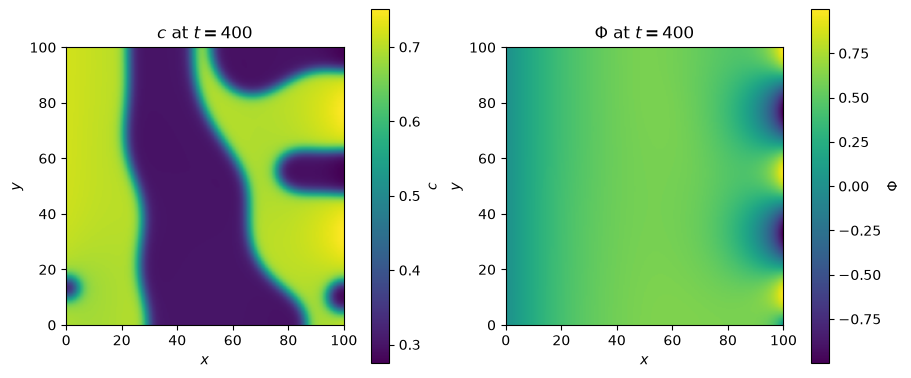

In [8]:
ts = np.concatenate([[0.0, 2.0, 5.0], np.arange(10.0, 401.0, 10.0)])
solve = lambda: ds.pdesolve(problem, ds.JIDA(), (0.0, 400.0), y0, saveat=ds.SaveAt(ts=ts))
for label in ("compile and run", "run"):
    start = time.perf_counter()
    sol = jax.block_until_ready(solve())
    print(f"{label}: {time.perf_counter() - start:.1f} s")
print(f"ok: {bool(sol.ok)}, {int(sol.stats.accepts)} steps")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.8), constrained_layout=True)
for ax, rows, name in [(axs[0], slice(0, n), "$c$"), (axs[1], slice(2 * n, 3 * n), r"$\Phi$")]:
    im = ax.imshow(sol.ys[-1][rows].reshape(shape).T, origin="lower", extent=(0, L, 0, L))
    fig.colorbar(im, ax=ax, label=name)
    ax.set(xlabel="$x$", ylabel="$y$", title=f"{name} at $t = 400$")
plt.show()

By $t = 400$ the species has separated into domains near $c_\alpha$ and $c_\beta$, and the potential follows the sine wave on the right edge.

## Check

We compare the free energy with the results that three other codes uploaded to [PFHub](https://pages.nist.gov/pfhub/simulations/6a.0/), at the times each one reports. Since no species crosses an edge, we also check that the total amount of species stays fixed.

t = 10, 100, 400: F = [154.95 130.37 103.8 ]
total species 5096.852321, drift 0.0e+00


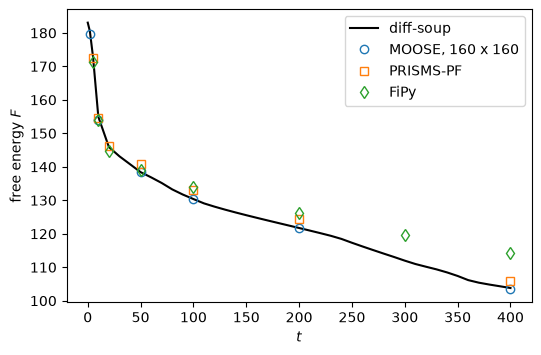

In [9]:
reference = {  # (t, F) read from the PFHub benchmark 6a uploads
    "MOOSE, 160 x 160": ([2, 10, 50, 100, 200, 400], [179.67, 154.11, 138.46, 130.31, 121.78, 103.61]),
    "PRISMS-PF": ([5, 10, 20, 50, 100, 200, 400], [172.56, 154.54, 146.12, 140.97, 133.08, 124.32, 105.75]),
    "FiPy": ([5, 10, 20, 50, 100, 200, 300, 400], [171.29, 154.03, 144.85, 138.93, 133.86, 126.07, 119.74, 114.28]),
}
F = np.array([free_energy(u) for u in sol.ys])
print("t = 10, 100, 400: F =", np.round(F[np.isin(ts, [10, 100, 400])], 2))
species = [float(u[:n] @ np.outer(wx, wy).ravel()) for u in sol.ys]
print(f"total species {species[0]:.6f}, drift {max(species) - min(species):.1e}")

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(ts, F, "k-", label="diff-soup")
for (name, (t_ref, F_ref)), marker in zip(reference.items(), "osd"):
    ax.plot(t_ref, F_ref, marker, mfc="none", label=name)
ax.set(xlabel="$t$", ylabel="free energy $F$")
ax.legend()
plt.show()

At $t = 10$, 100 and 400 our free energy is 154.95, 130.37 and 103.80, against 154.11, 130.31 and 103.61 for the $160 \times 160$ run of the MOOSE framework. All four curves agree up to $t = 50$, after which ours follows MOOSE while PRISMS-PF and FiPy lie higher. The total species does not drift, as zero flux on every edge requires.

## Algebraic fields and consistent initialization

We never gave $\mu$ or $\Phi$ an initial value, so `assemble_state` filled them with zeros, which satisfy neither constraint. The free energy shows how far this state is from the first one the solver saved.

In [10]:
print(f"F of the assembled state: {float(free_energy(y0)):.2f}")
print(f"F of the first saved state: {F[0]:.2f}")

F of the assembled state: 76.26
F of the first saved state: 183.06


The assembled state has the energy of $\Phi = 0$, which PRISMS-PF and FiPy report at $t = 0$ as 76.30 and 76.25. Before the first step, `pdesolve` holds $c$ fixed and solves the constraints for $\mu$ and $\Phi$, and `ds.project_algebraic` runs the same projection on any state.

SUCCESS residual norm 1.6e-15
largest change in c: 0.0e+00


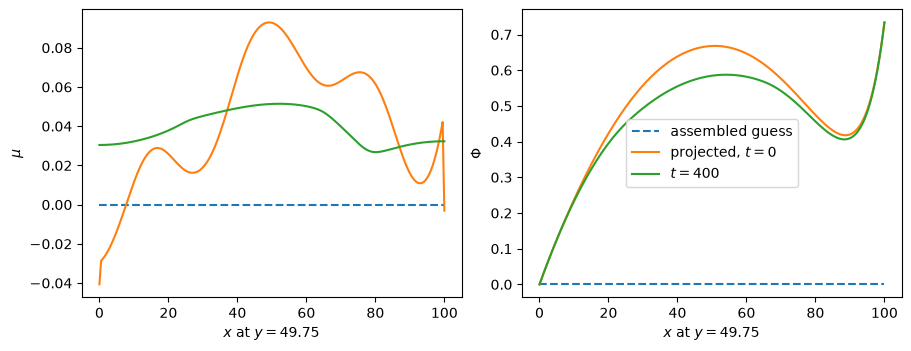

In [11]:
proj = ds.project_algebraic(problem, t=0.0, state=y0, seed=y0)
print(ds.AlgebraicProjectionStatus(int(proj.status)).name, f"residual norm {float(proj.residual_norm):.1e}")
print(f"largest change in c: {float(jnp.max(jnp.abs(proj.state - y0)[:n])):.1e}")

j = np.argmin(np.abs(ys - 50.0))  # the row of nodes nearest y = 50
fig, axs = plt.subplots(1, 2, figsize=(9, 3.4), constrained_layout=True)
for ax, rows, name in [(axs[0], slice(n, 2 * n), r"$\mu$"), (axs[1], slice(2 * n, 3 * n), r"$\Phi$")]:
    ax.plot(xs, y0[rows].reshape(shape)[:, j], "--", label="assembled guess")
    ax.plot(xs, proj.state[rows].reshape(shape)[:, j], label="projected, $t = 0$")
    ax.plot(xs, sol.ys[-1][rows].reshape(shape)[:, j], label="$t = 400$")
    ax.set(xlabel=f"$x$ at $y = {ys[j]:g}$", ylabel=name)
axs[1].legend()
plt.show()

The projection leaves $c$ untouched, and the projected potential runs from zero on the left edge to the sine wave on the right. On a problem with algebraic fields, turning the projection off is refused.

In [12]:
try:
    ds.pdesolve(problem, ds.JIDA(), (0.0, 1.0), y0, consistent_ic=False)
except ds.ConfigurationError as error:
    print(error)

this problem has algebraic rows; consistent_ic=False and ic_mode='assume_consistent' are not supported for it. Enable consistent initialization.


## Stop on the free energy

The uploads report $F$ only at their save times, but an event can find the moment $F$ falls through 120. Its `cond_fn` returns $F - 120$, which reads $\Phi$ as well as $c$, since algebraic fields are part of the state. `Bisection` locates the zero of that function between steps.

In [13]:
relaxed = ds.Event(
    cond_fn=lambda t, u, args, control=None: free_energy(u) - 120.0,
    root_finder=Bisection(),
    direction="down",
)
sol_event = ds.pdesolve(problem, ds.JIDA(), (0.0, 400.0), y0, event=relaxed)
t_stop = float(sol_event.terminal.t)
print(f"ok: {bool(sol_event.ok)}, stopped at t = {t_stop:.1f} with F = {float(free_energy(sol_event.terminal.y)):.4f}")
t_moose = np.interp(120.0, [119.91, 120.55], [224.0, 216.0])
print(f"MOOSE crosses 120 at t = {t_moose:.1f}, linear between its samples")

ok: True, stopped at t = 222.4 with F = 120.0000
MOOSE crosses 120 at t = 222.9, linear between its samples


Our crossing at $t = 222.4$ lands close to MOOSE's at 222.9, which is interpolated between samples eight time units apart.